# 22 — Regional covariance sensitivity: scalar versus diagonal BEKK

Compare **Poland, Czechia, Romania, Sweden and Hungary** in **USD and EUR** on the same frozen
**October 2014–September 2026** sample: **144 months** per system. Reuse the 20 verified scalar
fits from notebook 21 and estimate **20 diagonal fits**, retaining world-only and constant
world/local pricing restrictions. Only the covariance specification changes.

Use the existing **Miniconda base** kernel; no fetching, new packages or custom kernel. Hungary
uses the same common window as every other country. Keep the 321-month historical estimates separate.
Explicit currency pricing remains deferred; these are three-equity systems with zero alphas.

In [1]:
# Diagnostic/optimizer controls; all estimations use the fixed common sample.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70), (0.02, 0.96)]
MIXED_ALPHA = [0.04, 0.08, 0.03]
MIXED_BETA = [0.92, 0.80, 0.92]
MAX_ITER = 1600
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)  # 0: original notebook-03 robust QML; others: fixed sensitivities.
REUSE_FITS = True         # Revalidate cached fits; False forces estimation from all starts.
MODEL_VERSION = "regional_diagonal_bekk_constant_v1"
BASELINE_MANIFEST_SHA = "8c33fefefb16e3adc6a08e28af0cdcf40a5908be2ce5b1d0eb38bd5875928c7e"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 02 and 20 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import regional_pricing_baseline as scalar_engine
importlib.reload(scalar_engine)
import regional_covariance_sensitivity as engine
importlib.reload(engine)  # Reruns always use the engine currently on disk.

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
COUNTRY_ORDER = ["HU", "PL", "CZ", "RO", "SE"]
CURRENCIES = ["USD", "EUR"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
OUT = ROOT / "output" / "22_regional_covariance_sensitivity" / "2014-10_2026-09"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_sha = sha(Path(engine.__file__).read_bytes())
scalar_engine_sha = sha(Path(scalar_engine.__file__).read_bytes())
BASELINE = ROOT / "output" / "21_regional_pricing_baseline" / "2014-10_2026-09"
assert 2 <= TEST_LAGS <= 24 and HAC_LAGS[0] == 0 and all(0 <= h <= 24 for h in HAC_LAGS)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
print("Engine SHA-256:", engine_sha)

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
Engine SHA-256: 272b7678c7f81383f937e5abf64e7331563fd34f46fd8d2748e2db3ebf0d8212


## 1. Verify data and the unchanged scalar reference

Verify the regional and original Hungarian locks, the sealed dataset manifest, and all notebook-21
output hashes against its pinned manifest. A changed baseline stops the comparison. Validate every
saved scalar parameter vector and its likelihood on the exact same returns; no scalar fit is replaced.
The global portfolios, cash proxies, return units and calendar are identical across specifications.

In [2]:
def verify_inputs():
    locks, expected = {}, {}
    for name, wanted in LOCK_HASHES.items():
        raw = (ROOT / name).read_bytes()
        if sha(raw) != wanted: raise ValueError(f"Input lock changed: {name}")
        locks[name] = json.loads(raw)
        for path, checksum in locks[name]["files"].items():
            if path in expected and expected[path] != checksum: raise ValueError(f"Conflicting lock: {path}")
            expected[path] = checksum
    for path, checksum in expected.items():
        if sha((ROOT / path).read_bytes()) != checksum: raise ValueError(f"Frozen file changed: {path}")
    regional = locks["regional_dataset_inputs.json"]
    raw = (ROOT / regional["root"] / "manifest.json").read_bytes()
    assert sha(raw) == regional["manifest_sha256"] and json.loads(raw)["sealed"]
    baseline_raw = (BASELINE/"estimation_manifest.json").read_bytes()
    if sha(baseline_raw) != BASELINE_MANIFEST_SHA: raise ValueError("Notebook-21 manifest changed.")
    baseline_manifest = json.loads(baseline_raw)
    assert baseline_manifest["input_locks"] == LOCK_HASHES
    assert baseline_manifest["engine_sha256"] == scalar_engine_sha
    assert baseline_manifest["first"] == "2014-10" and baseline_manifest["last"] == "2026-09"
    assert baseline_manifest["settings"]["HAC_LAGS"] == list(HAC_LAGS)
    assert baseline_manifest["settings"]["TEST_LAGS"] == TEST_LAGS
    for name, checksum in baseline_manifest["outputs"].items():
        path = BASELINE/name
        if sha(path.read_bytes()) != checksum: raise ValueError(f"Changed scalar reference: {name}")
        expected[path.relative_to(ROOT).as_posix()] = checksum
    expected[(BASELINE/"estimation_manifest.json").relative_to(ROOT).as_posix()] = BASELINE_MANIFEST_SHA
    expected[Path(scalar_engine.__file__).relative_to(ROOT).as_posix()] = scalar_engine_sha
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes = {}, {}, {}, {}
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT / regional["root"] / "common" / f"{country}_{currency}.csv"
        relative = path.relative_to(ROOT).as_posix()
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[relative]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all()
        assert d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"] - d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local"]].to_numpy() * 100
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, y.std(axis=0, ddof=1), sha(raw)
        assert (scales[key] > 0).all() and np.linalg.eigvalsh(np.cov(y, rowvar=False)).min() > 0
        np.testing.assert_array_equal(y[:, :2], samples[("HU", currency)][:, :2])
for country in COUNTRY_ORDER:
    np.testing.assert_allclose(frames[(country, "USD")].r_local - frames[(country, "EUR")].r_local,
                               frames[(country, "USD")].fx_other, atol=1e-12, rtol=0)
display(pd.DataFrame([{"country": NAMES[c], "perspective": p, "first": str(months[0]),
    "last": str(months[-1]), "months": len(y), "assets": "World, US, national equity"}
    for (c, p), y in samples.items()]))
print("Verified", len(input_hashes), "unique frozen files; all ten input systems share 144 months.")

scalar_fits = {}
for key, y in samples.items():
    for model, partial in [("world_only", False), ("world_local", True)]:
        country, currency = key
        record = json.loads((BASELINE/f"fit_{country}_{currency}_{model}.json").read_text())
        config = record["config"]
        assert (config["country"], config["perspective"], config["model"], config["source_sha256"]) == (country, currency, model, source_hashes[key])
        assert config["engine_sha256"] == scalar_engine_sha
        assert record["fingerprint"] == sha(json.dumps(config, sort_keys=True).encode()+y.tobytes())
        theta = np.asarray(record["theta"])
        f = scalar_engine.filter_model(theta, y, scales[key], partial)
        assert abs(f["losses"].mean()-record["mean_nll"]) < 1e-8
        assert np.abs(f["scores"].mean(axis=0)).max() < 1e-4
        with np.load(BASELINE/f"parameters_{country}_{currency}_{model}.npz", allow_pickle=False) as saved:
            np.testing.assert_array_equal(theta, saved["theta"])
            for field in ["H", "mu", "errors", "scores"]:
                np.testing.assert_allclose(f[field], saved[field], atol=1e-12, rtol=0)
        scalar_fits[(*key, model)] = {"theta": theta, "filter": f, "partial": partial,
            "y": y, "scales": scales[key], "record": record}
print("Verified all 20 unchanged scalar reference fits.")

,country,perspective,first,last,months,assets
0,Hungary,USD,2014-10,2026-09,144,"World, US, national equity"
1,Hungary,EUR,2014-10,2026-09,144,"World, US, national equity"
2,Poland,USD,2014-10,2026-09,144,"World, US, national equity"
3,Poland,EUR,2014-10,2026-09,144,"World, US, national equity"
4,Czechia,USD,2014-10,2026-09,144,"World, US, national equity"
5,Czechia,EUR,2014-10,2026-09,144,"World, US, national equity"
6,Romania,USD,2014-10,2026-09,144,"World, US, national equity"
7,Romania,EUR,2014-10,2026-09,144,"World, US, national equity"
8,Sweden,USD,2014-10,2026-09,144,"World, US, national equity"
9,Sweden,EUR,2014-10,2026-09,144,"World, US, national equity"


Verified 881 unique frozen files; all ten input systems share 144 months.


Verified all 20 unchanged scalar reference fits.


## 2. Change the covariance process only

For asset order World, US, national equity, the unchanged pricing restrictions are

$$\mu_{W,t}=\lambda_W H_{WW,t},\qquad
\mu_{US,t}=\lambda_W H_{US,W,t}+\lambda_{US}H_{US,US,t},\qquad
\mu_{L,t}=\lambda_W H_{L,W,t}+\lambda_{L}H_{L,L,t}.$$

`world_only` fixes both local prices to zero; `world_local` estimates all three. Prices have unrestricted
sign. Returns are monthly excess log returns in percentage points, matching notebook 21.

**The new covariance equation is**

$$\boxed{H_t=CC'+A\varepsilon_{t-1}\varepsilon_{t-1}'A'+BH_{t-1}B',\quad
A=\operatorname{diag}(\sqrt{\alpha_i}),\quad B=\operatorname{diag}(\sqrt{\beta_i}).}$$

A free lower-triangular $C$ with positive diagonal makes the intercept positive definite. For each
asset, a softmax sets $\alpha_i>0$, $\beta_i>0$, $\alpha_i+\beta_i<1$. Thus
$|\sqrt{\alpha_i\alpha_j}+\sqrt{\beta_i\beta_j}|<1$ for every pair, ensuring covariance stationarity
for this diagonal recursion. Start at its implied long-run innovation covariance:

$$H_{0,ij}=\Sigma_{ij}=\frac{(CC')_{ij}}{1-\sqrt{\alpha_i\alpha_j}-\sqrt{\beta_i\beta_j}}.$$

This is the diagonal BEKK form of the [Engle–Kroner covariance family](https://doi.org/10.1017/S0266466600009063).
Here diagonal coefficients are restricted to be nonnegative; there are no asymmetric shock terms.
This is a covariance robustness check, not an exact reproduction of the paper's parameterisation.

There are **13 parameters** under world-only and **15** under world/local: six intercept coordinates,
six dynamic coordinates, and one or three prices. The scalar benchmark is exactly nested by setting
all $\alpha_i=\alpha$ and $\beta_i=\beta$, with $CC'=(1-\alpha-\beta)\Sigma$.

Both specifications are retained for sensitivity; the diagonal model has four extra dynamic
parameters. A lower likelihood loss alone is insufficient evidence for those extra parameters in
144 observations. Separate country systems do not impose a single pooled world risk price.

In [3]:
check_rows = []
for key, baseline in scalar_fits.items():
    country, currency, model = key
    y, partial, scale = baseline["y"], baseline["partial"], baseline["scales"]
    nested = engine.scalar_to_diagonal(baseline["theta"], partial)
    limits = np.asarray(engine.parameter_bounds(partial))
    assert ((nested >= limits[:, 0]-1e-10) & (nested <= limits[:, 1]+1e-10)).all()
    f = engine.filter_model(nested, y, scale, partial)
    for field in ["H", "mu", "losses"]:
        np.testing.assert_allclose(f[field], baseline["filter"][field], atol=1e-8, rtol=1e-10)
    theta = engine.initial_theta(y, scale, partial, MIXED_ALPHA, MIXED_BETA)
    theta += np.linspace(-.01, .015, len(theta))
    analytic = engine.objective(theta, y[:40], scale, partial)[1]
    numeric = engine.numerical_gradient(lambda x: engine.objective(x, y[:40], scale, partial)[0], theta)
    np.testing.assert_allclose(analytic, numeric, rtol=2e-5, atol=2e-6)
    restriction, J = engine.dynamic_restrictions(theta, scale, partial)
    numeric_J = np.vstack([engine.numerical_gradient(
        lambda x, i=i: engine.dynamic_restrictions(x, scale, partial)[0][i], theta) for i in range(4)])
    np.testing.assert_allclose(J, numeric_J, rtol=2e-5, atol=2e-7)
    check_rows.append({"country": country, "perspective": currency, "model": model,
        "max_gradient_error": np.abs(analytic-numeric).max(),
        "scalar_nesting_max_H_error": np.abs(f["H"]-baseline["filter"]["H"]).max(),
        "dynamic_Jacobian_max_error": np.abs(J-numeric_J).max()})
checks = pd.DataFrame(check_rows)
display(checks.groupby("perspective").max(numeric_only=True))
print("All 20 gradient, exact scalar-nesting and dynamic-restriction derivative checks pass.")

,max_gradient_error,scalar_nesting_max_H_error,dynamic_Jacobian_max_error
perspective,,,
EUR,6.018323e-09,5.684342e-14,1.329784e-11
USD,6.733933e-09,4.263256e-14,1.329784e-11


All 20 gradient, exact scalar-nesting and dynamic-restriction derivative checks pass.


## 3. Estimate the diagonal systems

Use the corresponding scalar optimum, three fixed common-dynamics starts and one unequal-dynamics
start. World/local also starts at the fitted diagonal world-only restriction. Inspect the spread of
starting-point likelihoods. The selected fit must beat both relevant nested restrictions.

Require optimizer success and maximum **projected gradient** below 0.0001. This is the box-constraint
KKT gradient: an outward-pointing score at an active bound is excluded. Save raw and projected
gradients separately. Bound-constrained point estimates can be reported, while their regular
standard errors and Wald tests are suppressed. This does not relax bounds or hide a convergence
failure. A lower nonconverged candidate stops selection. Failed starts receive a tighter optimizer
retry; all starts are deterministic. Multiple starts do not prove a global optimum.

Cached fits require matching engine/data/baseline fingerprints, likelihood, bounds and projected
gradient checks. Reuse affects computation time only; previous results are never overwritten.

In [4]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    for model, partial in [("world_only", False), ("world_local", True)]:
        print(f"{NAMES[country]} · {currency} · diagonal · {model}", flush=True)
        baseline = scalar_fits[(*key, model)]
        config = {"version": MODEL_VERSION, "engine_sha256": engine_sha, "scalar_engine_sha256": scalar_engine_sha,
            "country": country, "perspective": currency, "model": model, "source_sha256": source_hashes[key],
            "baseline_fit_sha256": sha((BASELINE/f"fit_{country}_{currency}_{model}.json").read_bytes()),
            "baseline_manifest_sha256": BASELINE_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]),
            "start_dynamics": START_DYNAMICS, "mixed_alpha": MIXED_ALPHA, "mixed_beta": MIXED_BETA,
            "max_iter": MAX_ITER, "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode()+y.tobytes())
        path = OUT/f"fit_{country}_{currency}_{model}.json"
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        limits = np.asarray(engine.parameter_bounds(partial))
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"])
            value, gradient = engine.objective(theta, y, scales[key], partial)
            projected = engine.projected_gradient(theta, gradient, limits)
            valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and np.abs(projected).max() < 1e-4 and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
            if not valid: record = None
        else: record = None
        if record is None:
            starts = [engine.scalar_to_diagonal(baseline["theta"], partial)]
            starts += [engine.initial_theta(y, scales[key], partial, a, b) for a, b in START_DYNAMICS]
            starts += [engine.initial_theta(y, scales[key], partial, MIXED_ALPHA, MIXED_BETA)]
            if partial:
                theta0 = fits[(*key, "world_only")]["theta"]
                starts.insert(0, np.r_[theta0[0], 0., 0., theta0[1:]])
            best, runs = engine.fit_starts(y, scales[key], partial, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp")
            temp.write_text(json.dumps(record, indent=2, sort_keys=True)+"\n")
            temp.replace(path)
        else: print("  verified cached fit", flush=True)
        theta = np.asarray(record["theta"])
        f = engine.filter_model(theta, y, scales[key], partial)
        assert np.linalg.eigvalsh(f["H"]).min() > 0
        assert f["losses"].sum() <= baseline["filter"]["losses"].sum()+1e-5
        if partial: assert f["losses"].sum() <= fits[(*key, "world_only")]["filter"]["losses"].sum()+1e-5
        fits[(*key, model)] = {"theta": theta, "filter": f, "partial": partial,
            "y": y, "scales": scales[key], "record": record}
        start_rows.extend({"country": country, "perspective": currency, "model": model, **r} for r in record["starts"])
starts_table = pd.DataFrame(start_rows, columns=["country", "perspective", "model", "start", "success", "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
display(starts_table.groupby(["country", "perspective", "model"]).agg(starts=("start", "count"),
    successes=("success", "sum"), best_mean_NLL=("mean_nll", "min"), worst_mean_NLL=("mean_nll", "max"),
    worst_projected_gradient=("max_projected_gradient", "max")).round(7))
all_fits = {**{("scalar", *k): f for k, f in scalar_fits.items()}, **{("diagonal", *k): f for k, f in fits.items()}}

Hungary · USD · diagonal · world_only


  verified cached fit


Hungary · USD · diagonal · world_local


  verified cached fit


Hungary · EUR · diagonal · world_only


  verified cached fit


... (31 outputs left out)

  verified cached fit

Sweden · EUR · diagonal · world_local


  verified cached fit

starts  successes  best_mean_NLL  \
country perspective model                                           
CZ      EUR         world_local       6          6       6.755271   
                    world_only        5          5       6.788016   
        USD         world_local       6          6       6.902923   
                    world_only        5          5       6.945086   
HU      EUR         world_local       6          6       7.139987   
                    world_only        5          5       7.167474   
        USD         world_local       6          6       7.265585   
                    world_only        5          5       7.297847   
PL      EUR         world_local       6          6       7.003936   
                    world_only        5          5       7.020167   
        USD         world_local       6          6       7.123303   
                    world_only        5          5       7.146566   
RO      EUR         world_local       6          6       6.943471   
                    world_only        5          5       6.980434   
        USD         world_local       6          6       7.089373   
                    world_only        5          5       7.134734   
SE      EUR         world_local       6          6       6.454951   
                    world_only        5          5       6.475253   
        USD         world_local       6          6       6.536981   
                    world_only        5          5       6.558632   

                                 worst_mean_NLL  worst_projected_gradient  
country perspective model                                                  
CZ      EUR         world_local        6.755271              3.000000e-07  
                    world_only         6.788016              7.000000e-07  
        USD         world_local        6.923585              1.200000e-06  
                    world_only         6.954692              1.400000e-06  
HU      EUR         world_local        7.156776              8.000000e-07  
                    world_only         7.197644              2.100000e-06  
        USD         world_local        7.290882              1.200000e-06  
                    world_only         7.320838              8.000000e-07  
PL      EUR         world_local        7.072020              1.700000e-06  
                    world_only         7.027541              7.000000e-07  
        USD         world_local        7.123303              2.000000e-07  
                    world_only         7.159035              4.000000e-07  
RO      EUR         world_local        6.943471              5.000000e-07  
                    world_only         6.998168              4.000000e-07  
        USD         world_local        7.104523              4.500000e-06  
                    world_only         7.134734              7.000000e-07  
SE      EUR         world_local        6.454951              5.000000e-07  
                    world_only         6.482105              1.000000e-06  
        USD         world_local        6.542220              1.200000e-06  
                    world_only         6.558632              1.000000e-06

## 4. Curvature, uncertainty and restrictions under both covariance models

Use the same robust QML score-OPG sandwich (lag 0) and fixed Bartlett score-HAC lags **3, 6, 12**
as notebook 21. Recompute scalar inference without changing its fit, verifying that its results agree
with the saved reference. Compare two Hessian steps and suppress inference at bounds, nonpositive
or ill-conditioned curvature, unstable Hessians or price standard errors. Save the affected coordinates.

Under diagonal BEKK, also test **common alpha and common beta across the three assets**: four
physical-coefficient restrictions, with an analytic delta-method Jacobian, as in notebook 04.
Suppress this Wald test if its restriction covariance is singular or ill-conditioned. Zero local-price
tests remain separate: both local prices jointly, the national price, and the US local price.

These are exploratory asymptotic tests; pricing/Wald p-values are unadjusted. There is no ordinary
Gaussian likelihood-ratio chi-square p-value under non-normal QML. Score-HAC does not repair model
misspecification. With only 144 months, flexibility can create weak identification or bound solutions.

In [5]:
fit_rows, price_rows, test_rows, inference_rows, boundary_rows, dynamics_rows = [], [], [], [], [], []
for (covariance, country, currency, model), fit in all_fits.items():
    implementation = engine if covariance == "diagonal" else scalar_engine
    theta, f, y, partial = fit["theta"], fit["filter"], fit["y"], fit["partial"]
    info = implementation.inference(theta, y, fit["scales"], partial, f, HAC_LAGS)
    fit["inference"] = info
    tags = {"covariance": covariance, "country": country, "perspective": currency, "model": model}
    labels = ["World price scaled", "US local price scaled", "National price scaled"][:3 if partial else 1]
    labels += ["log L11", "L21", "log L22", "L31", "L32", "log L33"]
    labels += [f"{asset} {parameter} logit" for asset in (["World", "US", "National"] if covariance == "diagonal" else ["Shared"])
               for parameter in ["alpha", "beta"]]
    limits = np.asarray(implementation.parameter_bounds(partial))
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({**tags, "parameter": label, "coordinate": theta[j], "lower": limits[j, 0],
        "upper": limits[j, 1], "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    gradient = f["scores"].mean(axis=0)
    projected = engine.projected_gradient(theta, gradient, limits)
    loglik = -f["losses"].sum()
    fit_rows.append({**tags, "n": len(y), "parameters": len(theta), "loglik": loglik,
        "AIC": -2*loglik+2*len(theta), "BIC": -2*loglik+np.log(len(y))*len(theta),
        "max_abs_gradient": np.abs(gradient).max(), "max_projected_gradient": np.abs(projected).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(),
        "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    for j, asset in enumerate(["World", "US", "National"]):
        alpha, beta = np.broadcast_to(f["alpha"], 3)[j], np.broadcast_to(f["beta"], 3)[j]
        dynamics_rows.append({**tags, "asset": asset, "alpha": alpha, "beta": beta, "persistence": alpha+beta})
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"]})
        for j, risk in enumerate(["World", "US local", "National local"][:3 if partial else 1]):
            value, se = f["prices"][j], engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            price_rows.append({**tags, "risk": risk, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan,
                "ci95_low": value-1.96*se, "ci95_high": value+1.96*se, "inference_ready": ready, "reason": estimate["reason"]})
        restrictions = []
        if partial:
            for name, ids in [("Both local prices zero", [1, 2]), ("National local price zero", [2]), ("US local price zero", [1])]:
                restrictions.append((name, theta[ids], V[np.ix_(ids, ids)]))
        if covariance == "diagonal":
            r, J = engine.dynamic_restrictions(theta, fit["scales"], partial)
            restrictions.append(("Common covariance dynamics", r, J@V@J.T))
        for name, r, variance in restrictions:
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = r@np.linalg.solve(variance, r) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "Wald_statistic": statistic,
                "df": len(r), "p_value": chi2.sf(statistic, len(r)) if valid else np.nan,
                "inference_ready": valid, "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
fit_table, price_table, tests, inference_audit, boundary_audit, dynamics = map(pd.DataFrame,
    [fit_rows, price_rows, test_rows, inference_rows, boundary_rows, dynamics_rows])
# Scalar reference values must be unchanged, including unavailable inference.
old_prices = pd.read_csv(BASELINE/"risk_prices.csv", float_precision="round_trip")
for row in old_prices.itertuples():
    a = price_table.loc[(price_table.covariance == "scalar") & (price_table.country == row.country)
        & (price_table.perspective == row.perspective) & (price_table.model == row.model)
        & (price_table.risk == row.risk) & (price_table.HAC_lag == row.HAC_lag)].iloc[0]
    np.testing.assert_allclose([a.estimate, a.robust_se, a.p_value], [row.estimate, row.robust_se, row.p_value],
        atol=1e-12, rtol=0, equal_nan=True)
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "ready", "reason"]).size().rename("systems"))
display(boundary_audit.query("covariance == 'diagonal' and near_bound").set_index(["country", "perspective", "model"]))
display(dynamics.query("covariance == 'diagonal' and model == 'world_local'")
    .set_index(["country", "perspective", "asset"])[["alpha", "beta", "persistence"]].round(4))

covariance  ready  reason                                    
diagonal    False  parameter bound                                8
                   parameter bound; ill-conditioned curvature     3
            True   numerically ready                              9
scalar      False  parameter bound                                4
            True   numerically ready                             16
Name: systems, dtype: int64

covariance      parameter  coordinate  lower  \
country perspective model                                                      
HU      USD         world_only    diagonal        log L33        -6.0   -6.0   
                    world_local   diagonal        log L33        -6.0   -6.0   
        EUR         world_local   diagonal  US beta logit       -10.0  -10.0   
PL      USD         world_only    diagonal        log L33        -6.0   -6.0   
                    world_local   diagonal        log L33        -6.0   -6.0   
        EUR         world_only    diagonal        log L33        -6.0   -6.0   
                    world_only    diagonal  US beta logit       -10.0  -10.0   
                    world_local   diagonal  US beta logit       -10.0  -10.0   
CZ      USD         world_local   diagonal        log L33        -6.0   -6.0   
        EUR         world_only    diagonal        log L33        -6.0   -6.0   
                    world_local   diagonal        log L33        -6.0   -6.0   
SE      EUR         world_local   diagonal        log L33        -6.0   -6.0   

                                 upper  distance_to_bound  near_bound  
country perspective model                                              
HU      USD         world_only     3.0                0.0        True  
                    world_local    3.0                0.0        True  
        EUR         world_local   10.0                0.0        True  
PL      USD         world_only     3.0                0.0        True  
                    world_local    3.0                0.0        True  
        EUR         world_only     3.0                0.0        True  
                    world_only    10.0                0.0        True  
                    world_local   10.0                0.0        True  
CZ      USD         world_local    3.0                0.0        True  
        EUR         world_only     3.0                0.0        True  
                    world_local    3.0                0.0        True  
SE      EUR         world_local    3.0                0.0        True

alpha    beta  persistence
country perspective asset                                
HU      USD         World     0.1041  0.1076       0.2117
                    US        0.1151  0.0208       0.1359
                    National  0.0742  0.7410       0.8153
        EUR         World     0.1223  0.0173       0.1396
                    US        0.1200  0.0000       0.1200
                    National  0.1068  0.6872       0.7940
PL      USD         World     0.1286  0.0532       0.1818
                    US        0.1578  0.0059       0.1637
                    National  0.1295  0.5984       0.7279
        EUR         World     0.1797  0.0077       0.1874
                    US        0.2003  0.0000       0.2004
                    National  0.1686  0.6188       0.7874
CZ      USD         World     0.1062  0.0593       0.1655
                    US        0.1239  0.0011       0.1250
                    National  0.1327  0.2277       0.3604
        EUR         World     0.0880  0.0705       0.1585
                    US        0.0939  0.0042       0.0982
                    National  0.2009  0.1486       0.3496
RO      USD         World     0.1220  0.0746       0.1966
                    US        0.1460  0.0097       0.1557
                    National  0.0404  0.2770       0.3175
        EUR         World     0.1469  0.0171       0.1640
                    US        0.1649  0.0055       0.1704
                    National  0.0696  0.2549       0.3245
SE      USD         World     0.0501  0.7249       0.7750
                    US        0.0672  0.6434       0.7107
                    National  0.0663  0.8427       0.9090
        EUR         World     0.1443  0.3477       0.4920
                    US        0.1590  0.2523       0.4114
                    National  0.2164  0.1125       0.3289

## 5. Compare residual adequacy on the same footing

Apply the same marginal standardised-innovation, squared-innovation and ARCH screens to both
covariance models, and the same Cholesky-whitened cross-products. Holm families are covariance
specification × pricing restriction × investor currency × diagnostic type (15 asset/pair series).
Report raw and adjusted p-values. Shared raw world returns yield different fitted innovations.
These are approximate screens with no full estimated-GARCH parameter correction. Lack of a
rejection in a short sample is not model validation or evidence that currency risk is unpriced.

In [6]:
residual_rows, cross_rows = [], []
for (covariance, country, currency, model), fit in all_fits.items():
    f = fit["filter"]
    z = f["errors"] / np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    for j, asset in enumerate(["World", "US", "National"]):
        lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
        residual_rows.append({"covariance": covariance, "country": country, "perspective": currency, "model": model, "asset": asset,
            "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1), "LB_z_p": lb(z[:, j]),
            "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in [(0, 1), (0, 2), (1, 2)]:
        product = white[:, i]*white[:, j]
        cross_rows.append({"covariance": covariance, "country": country, "perspective": currency, "model": model,
            "pair": f"{['World', 'US', 'National'][i]}/{['World', 'US', 'National'][j]}",
            "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for table, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in table.groupby(["covariance", "model", "perspective"]).groups.items():
        for column in columns:
            table.loc[idx, column+"_holm"] = multipletests(table.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'world_local' and asset == 'National'")
    .set_index(["country", "perspective", "covariance"])[["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

z_mean     z_sd   LB_z_p  LB_z_p_holm  \
country perspective covariance                                           
HU      USD         scalar     -0.01922  1.00758  0.62083          1.0   
        EUR         scalar     -0.00887  1.00588  0.49169          1.0   
PL      USD         scalar     -0.04636  1.01237  0.44851          1.0   
        EUR         scalar     -0.04591  1.02051  0.48654          1.0   
CZ      USD         scalar     -0.00910  1.01148  0.80264          1.0   
        EUR         scalar      0.00196  1.01141  0.46686          1.0   
RO      USD         scalar      0.02213  1.00922  0.15900          1.0   
        EUR         scalar      0.03203  1.00890  0.21915          1.0   
SE      USD         scalar     -0.06268  1.01018  0.93016          1.0   
        EUR         scalar     -0.07993  1.01837  0.80411          1.0   
HU      USD         diagonal   -0.01698  1.00876  0.68023          1.0   
        EUR         diagonal   -0.01656  1.00162  0.63821          1.0   
PL      USD         diagonal   -0.04571  1.01317  0.43527          1.0   
        EUR         diagonal   -0.06326  1.01739  0.45522          1.0   
CZ      USD         diagonal   -0.00264  1.01159  0.79203          1.0   
        EUR         diagonal    0.03111  1.00315  0.48227          1.0   
RO      USD         diagonal   -0.00930  1.01154  0.14604          1.0   
        EUR         diagonal    0.01244  1.01187  0.21478          1.0   
SE      USD         diagonal   -0.03572  1.04394  0.89925          1.0   
        EUR         diagonal   -0.05336  1.01068  0.86570          1.0   

                                ARCH_LM_p  ARCH_LM_p_holm  
country perspective covariance                             
HU      USD         scalar        0.49309             1.0  
        EUR         scalar        0.38844             1.0  
PL      USD         scalar        0.16765             1.0  
        EUR         scalar        0.23131             1.0  
CZ      USD         scalar        0.21297             1.0  
        EUR         scalar        0.25688             1.0  
RO      USD         scalar        0.89459             1.0  
        EUR         scalar        0.97115             1.0  
SE      USD         scalar        0.70154             1.0  
        EUR         scalar        0.89038             1.0  
HU      USD         diagonal      0.62269             1.0  
        EUR         diagonal      0.66774             1.0  
PL      USD         diagonal      0.44803             1.0  
        EUR         diagonal      0.13342             1.0  
CZ      USD         diagonal      0.18379             1.0  
        EUR         diagonal      0.19263             1.0  
RO      USD         diagonal      0.84243             1.0  
        EUR         diagonal      0.96137             1.0  
SE      USD         diagonal      0.93831             1.0  
        EUR         diagonal      0.92163             1.0

## 6. Fit and premium sensitivity relative to Hungary

Compare AIC/BIC **within each country's same return vector and investor currency**. Negative
diagonal-minus-scalar differences favour diagonal dynamics; a lower raw loss is guaranteed by
nesting when optimized adequately. AIC/BIC levels across different countries are not comparable.
Keep information criteria, inference validity and residual adequacy as separate assessments.

World and national-local premium contributions still sum to the fitted mean. The national-local
term is not an explicit FX premium. Record signs and magnitudes under both covariance models,
and distinguish unavailable tests from non-rejections. No formal cross-country price test is made.

AIC/BIC use the full nominal parameter counts even for bound solutions; treat their rankings as descriptive.
The extra parameters do not resolve the numerical inference limitations by themselves.

loglik_gain  delta_AIC  delta_BIC
country perspective                                   
CZ      EUR               2.5039     2.9922    14.8715
        USD               2.5902     2.8195    14.6988
HU      EUR               1.7422     4.5156    16.3948
        USD               1.7923     4.4154    16.2946
PL      EUR               1.1467     5.7067    17.5859
        USD               2.9883     2.0233    13.9026
RO      EUR               0.9663     6.0674    17.9466
        USD               2.0677     3.8646    15.7438
SE      EUR               4.4456    -0.8913    10.9880
        USD               4.2221    -0.4443    11.4350

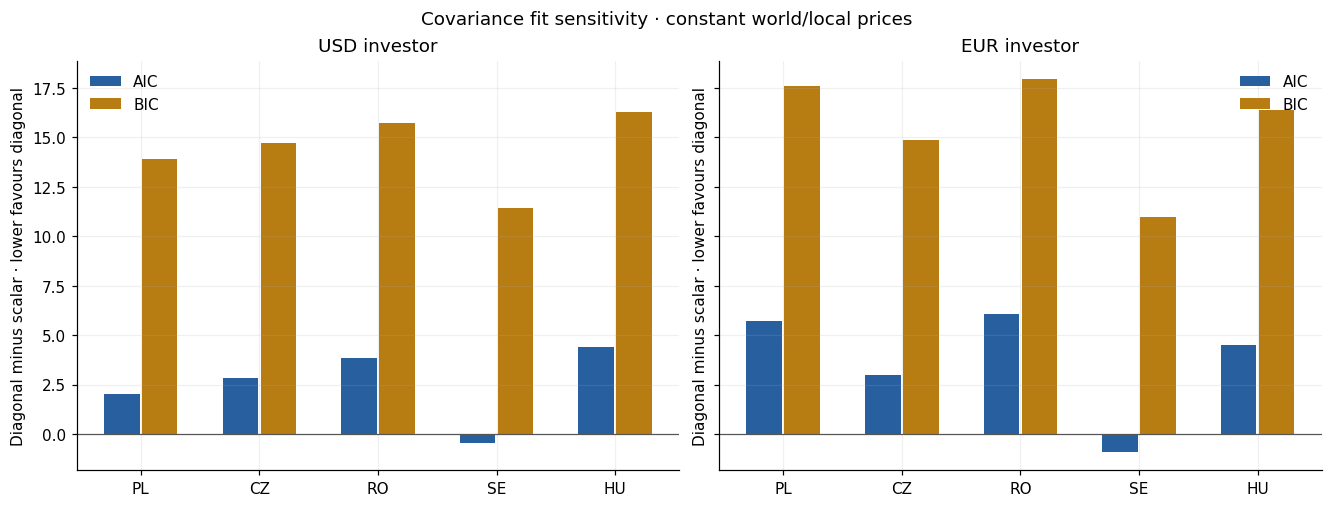

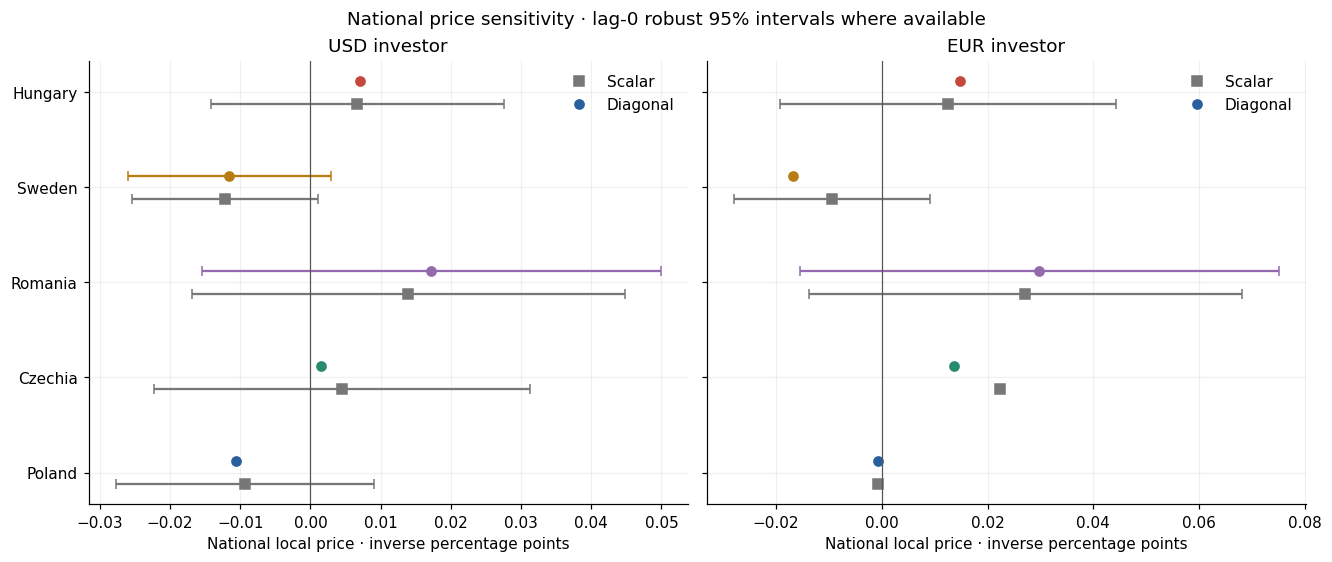

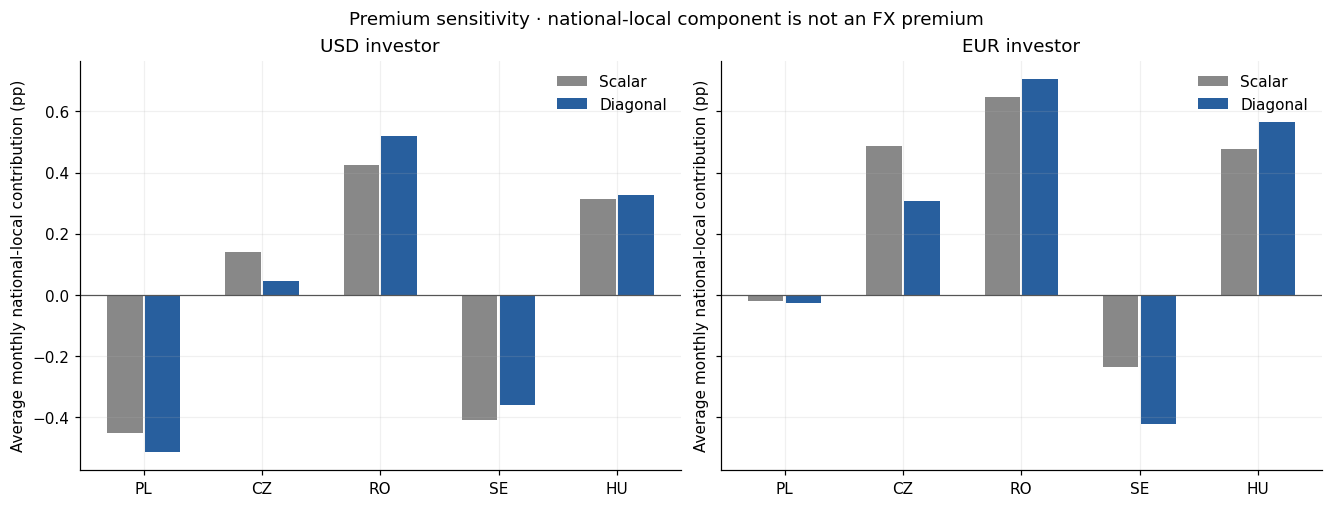

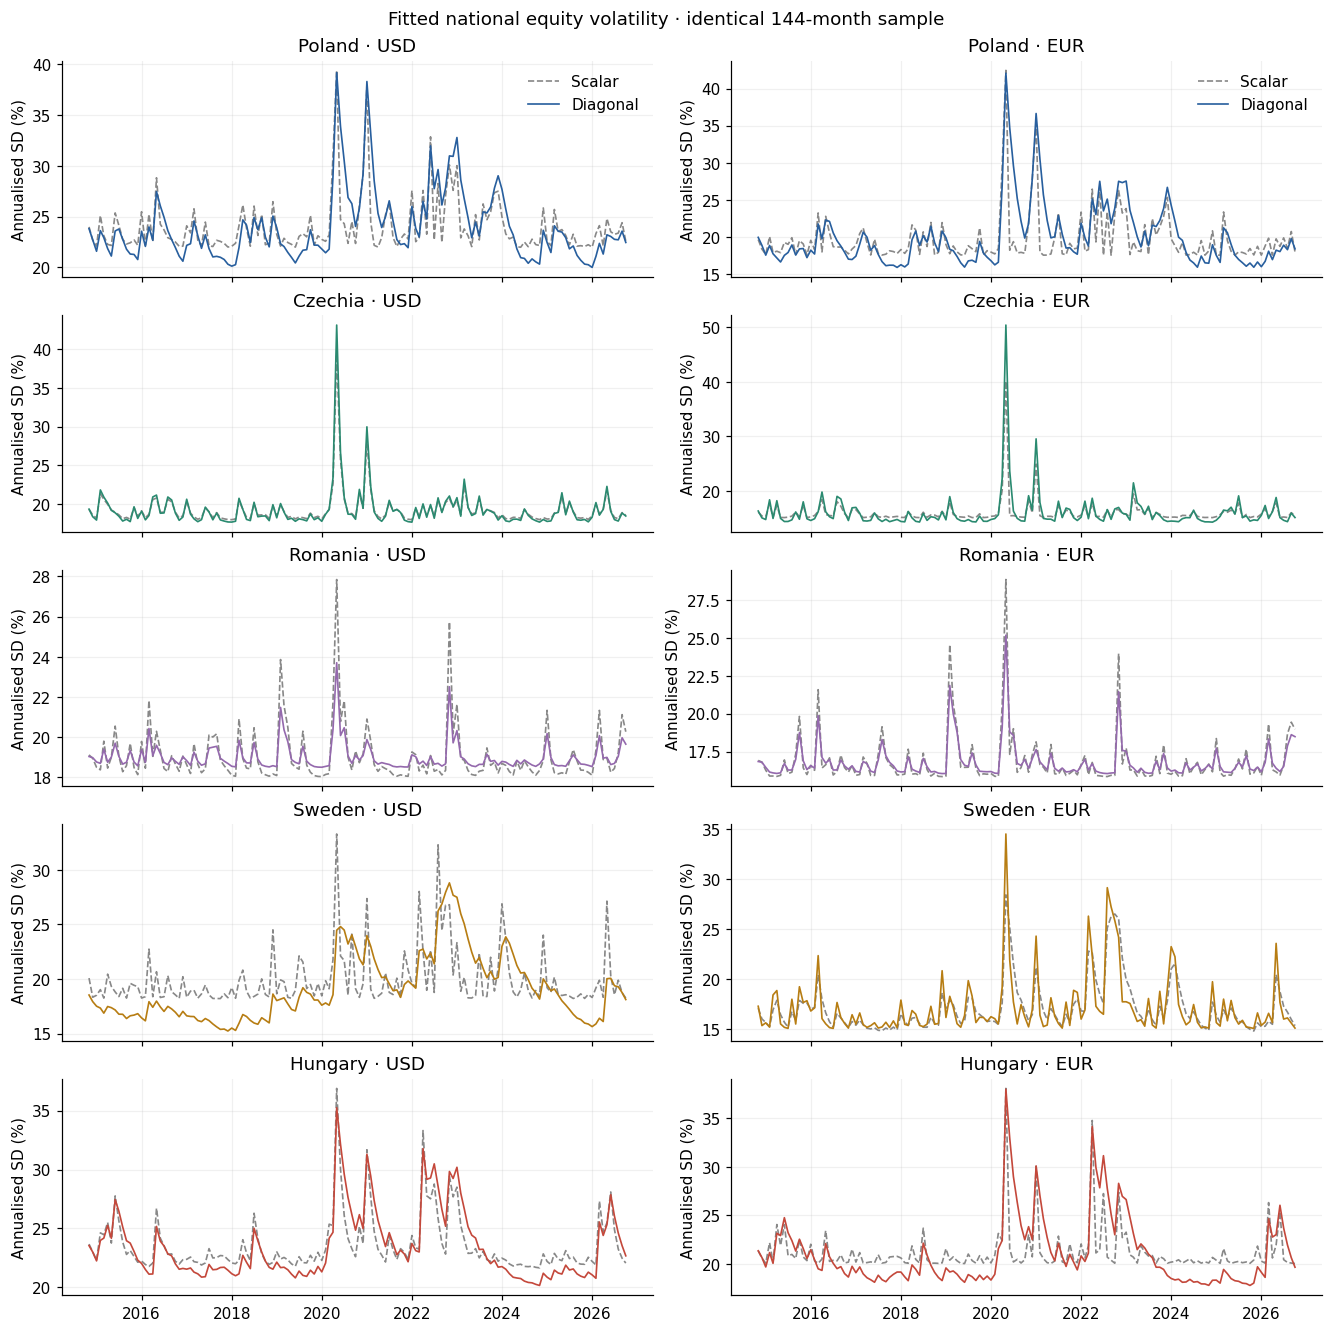

In [7]:
premium_rows, summary_rows = [], []
for (covariance, country, currency, model), fit in all_fits.items():
    f = fit["filter"]
    world, local = f["prices"][0]*f["H"][:, 2, 0], f["prices"][2]*f["H"][:, 2, 2]
    np.testing.assert_allclose(world+local, f["mu"][:, 2], atol=1e-12, rtol=0)
    premium_rows.extend({"month": str(month), "covariance": covariance, "country": country,
        "perspective": currency, "model": model, "world_premium_pp": world[t], "local_premium_pp": local[t],
        "fitted_mean_pp": f["mu"][t, 2], "world_covariance_pp2": f["H"][t, 2, 0],
        "own_variance_pp2": f["H"][t, 2, 2], "national_vol_annualised_pp": np.sqrt(12*f["H"][t, 2, 2]),
        "world_US_correlation": f["H"][t, 0, 1]/np.sqrt(f["H"][t, 0, 0]*f["H"][t, 1, 1])} for t, month in enumerate(months))
    if model == "world_local":
        choose = lambda name, lag: tests.loc[(tests.covariance == covariance) & (tests.country == country)
            & (tests.perspective == currency) & (tests.model == model) & (tests.restriction == name) & (tests.HAC_lag == lag), "p_value"].iloc[0]
        tags = (residuals.covariance == covariance) & (residuals.country == country) & (residuals.perspective == currency) & (residuals.model == model)
        r = residuals.loc[tags]
        c = cross.loc[(cross.covariance == covariance) & (cross.country == country) & (cross.perspective == currency) & (cross.model == model)]
        summary_rows.append({"covariance": covariance, "country": country, "name": NAMES[country], "perspective": currency,
            "months": len(months), "world_price": f["prices"][0], "national_local_price": f["prices"][2],
            "mean_world_premium_pp": world.mean(), "mean_local_premium_pp": local.mean(), "mean_fitted_premium_pp": f["mu"][:, 2].mean(),
            "local_joint_p_QML": choose("Both local prices zero", 0), "local_joint_p_HAC12": choose("Both local prices zero", 12),
            "national_local_p_QML": choose("National local price zero", 0),
            "national_local_p_HAC12": choose("National local price zero", 12),
            "common_dynamics_p_QML": choose("Common covariance dynamics", 0) if covariance == "diagonal" else np.nan,
            "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"], "inference_reason": fit["inference"]["estimates"][0]["reason"],
            "mean_flags_raw_5pct": int(r.LB_z_p.lt(.05).sum()), "mean_flags_holm_5pct": int(r.LB_z_p_holm.lt(.05).sum()),
            "variance_flags_raw_5pct": int((r.LB_z_squared_p.lt(.05) | r.ARCH_LM_p.lt(.05)).sum()),
            "variance_flags_holm_5pct": int((r.LB_z_squared_p_holm.lt(.05) | r.ARCH_LM_p_holm.lt(.05)).sum()),
            "cross_flags_raw_5pct": int(c.LB_product_p.lt(.05).sum()), "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
premiums, summary = pd.DataFrame(premium_rows), pd.DataFrame(summary_rows)
comparison_rows = []
for (country, currency, model), group in fit_table.groupby(["country", "perspective", "model"]):
    g = group.set_index("covariance")
    comparison_rows.append({"country": country, "perspective": currency, "model": model,
        "scalar_AIC": g.loc["scalar", "AIC"], "diagonal_AIC": g.loc["diagonal", "AIC"],
        "delta_AIC": g.loc["diagonal", "AIC"]-g.loc["scalar", "AIC"],
        "scalar_BIC": g.loc["scalar", "BIC"], "diagonal_BIC": g.loc["diagonal", "BIC"],
        "delta_BIC": g.loc["diagonal", "BIC"]-g.loc["scalar", "BIC"],
        "loglik_gain": g.loc["diagonal", "loglik"]-g.loc["scalar", "loglik"]})
comparison = pd.DataFrame(comparison_rows)
display(comparison.query("model == 'world_local'").set_index(["country", "perspective"])[["loglik_gain", "delta_AIC", "delta_BIC"]].round(4))
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional covariance notebook 22"})
    figure_files.append(name)
    plt.show()
    plt.close()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    c = comparison.query("model == 'world_local' and perspective == @currency").set_index("country").loc[list(NAMES)]
    x = np.arange(5)
    ax.bar(x-.16, c.delta_AIC, width=.3, label="AIC", color="#285f9e")
    ax.bar(x+.16, c.delta_BIC, width=.3, label="BIC", color="#b77d13")
    ax.axhline(0, color="#555555", lw=.8)
    ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} investor", ylabel="Diagonal minus scalar · lower favours diagonal")
    ax.legend(frameon=False)
fig.suptitle("Covariance fit sensitivity · constant world/local prices")
save_plot("01_information_criteria.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    for covariance, offset, marker in [("scalar", -.12, "s"), ("diagonal", .12, "o")]:
        p = price_table.query("model == 'world_local' and risk == 'National local' and HAC_lag == 0 and perspective == @currency and covariance == @covariance").set_index("country")
        for i, country in enumerate(NAMES):
            value, color = p.loc[country], ("#777777" if covariance == "scalar" else COLORS[country])
            ax.plot(value.estimate, i+offset, marker, color=color, label=covariance.capitalize() if i == 0 else None)
            if value.inference_ready: ax.errorbar(value.estimate, i+offset, xerr=1.96*value.robust_se, color=color, capsize=3)
    ax.axvline(0, color="#555555", lw=.8)
    ax.set(yticks=range(5), yticklabels=list(NAMES.values()), title=f"{currency} investor", xlabel="National local price · inverse percentage points")
    ax.legend(frameon=False)
fig.suptitle("National price sensitivity · lag-0 robust 95% intervals where available")
save_plot("02_national_risk_prices.png")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True, layout="constrained")
for ax, currency in zip(axes, CURRENCIES):
    x = np.arange(5)
    for covariance, offset, color in [("scalar", -.16, "#888888"), ("diagonal", .16, "#285f9e")]:
        p = summary.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        ax.bar(x+offset, p.mean_local_premium_pp, width=.3, color=color, label=covariance.capitalize())
    ax.axhline(0, color="#555555", lw=.8)
    ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} investor", ylabel="Average monthly national-local contribution (pp)")
    ax.legend(frameon=False)
fig.suptitle("Premium sensitivity · national-local component is not an FX premium")
save_plot("03_local_premiums.png")

fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
for row, country in enumerate(NAMES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        for covariance, collection, color, style in [("Scalar", scalar_fits, "#888888", "--"), ("Diagonal", fits, COLORS[country], "-")]:
            f = collection[(country, currency, "world_local")]["filter"]
            ax.plot(months.to_timestamp("M"), np.sqrt(12*f["H"][:, 2, 2]), label=covariance, color=color, ls=style, lw=1.1)
        ax.set(title=f"{NAMES[country]} · {currency}", ylabel="Annualised SD (%)")
        if row == 0: ax.legend(frameon=False)
fig.suptitle("Fitted national equity volatility · identical 144-month sample")
save_plot("04_conditional_volatility.png")

## 7. Final comparison and reproducible outputs

Compare the same five countries under both covariance specifications. Report bound/curvature
problems as unavailable inference, not insignificant prices. Joint local-price tests can be driven
by the US term; they do not establish that the national term is priced. Preserve all fixed HAC
results and both fitted paths for the next FX stage. USD/EUR are related views of the same data.

Keep scalar as a parsimonious reference and diagonal as a sensitivity; criterion and residual
tables describe the evidence rather than impose an automatic winner. Explicit FX pricing and
the previously used five-factor covariance alternatives belong to the later regional notebooks.

In [8]:
display(summary.set_index(["name", "perspective", "covariance"])[["national_local_price", "mean_local_premium_pp",
    "national_local_p_QML", "national_local_p_HAC12", "local_joint_p_QML", "common_dynamics_p_QML", "numerical_inference_ready"]].round(5))
display(summary.set_index(["name", "perspective", "covariance"])[["inference_reason", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"implementation_checks.csv": checks, "starting_points.csv": starts_table, "fit_summary.csv": fit_table,
    "risk_prices.csv": price_table, "restriction_tests.csv": tests, "dynamics.csv": dynamics,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": boundary_audit, "residual_diagnostics.csv": residuals,
    "cross_covariance_diagnostics.csv": cross, "premium_components.csv": premiums,
    "model_comparison.csv": comparison, "common_comparison.csv": summary}
for name, table in tables.items(): table.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files = []
for (covariance, country, currency, model), fit in all_fits.items():
    name = f"parameters_{covariance}_{country}_{currency}_{model}.npz"
    f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"],
        target=f["target"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and sha(Path(engine.__file__).read_bytes()) == engine_sha
outputs = [*tables, *figure_files, *parameter_files] + [f"fit_{c}_{p}_{m}.json" for c, p, m in fits]
metadata = {"notebook": "22_regional_covariance_sensitivity.ipynb", "model_version": MODEL_VERSION,
    "engine": "regional_covariance_sensitivity.py", "engine_sha256": engine_sha,
    "scalar_engine_sha256": scalar_engine_sha, "baseline_manifest_sha256": BASELINE_MANIFEST_SHA,
    "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "estimated_diagonal_fits": len(fits), "scalar_reference_fits": len(scalar_fits),
    "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MIXED_ALPHA": MIXED_ALPHA, "MIXED_BETA": MIXED_BETA,
        "MAX_ITER": MAX_ITER, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Offline; identical 144 months including Hungary; scalar references unchanged",
        "World-only and world/local prices constant; zero alphas; three equities; explicit FX pricing deferred",
        "Diagonal covariance adds four parameters; physical common-dynamics Wald uses delta method",
        "Constrained optimizer uses projected gradient; raw gradients saved and bound inference suppressed",
        "Primary QML, fixed HAC 3/6/12; residual screens do not validate the model"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+"\n")
main = comparison.query("model == 'world_local'")
unready = summary.loc[summary.covariance == "diagonal", "numerical_inference_ready"].eq(False).sum()
display(Markdown(f"**Completed:** {len(fits)} diagonal fits compared with {len(scalar_fits)} unchanged scalar references, "
    f"all on **{months[0]}–{months[-1]} ({len(months)} months)** in base. "
    f"For world/local models, diagonal has lower AIC in **{int(main.delta_AIC.lt(0).sum())}/10** systems "
    f"and lower BIC in **{int(main.delta_BIC.lt(0).sum())}/10**. "
    f"**{unready}/10** diagonal world/local systems have suppressed primary numerical inference. "
    f"Saved {len(tables)} tables, {len(figure_files)} charts and all fitted arrays in `{OUT.relative_to(ROOT)}`. "
    "Frozen data and notebook-21 outputs remain unchanged. Next: add explicit currency risk while retaining covariance sensitivity."))

national_local_price  mean_local_premium_pp  \
name    perspective covariance                                                
Hungary USD         scalar                   0.00668                0.31269   
        EUR         scalar                   0.01252                0.47644   
Poland  USD         scalar                  -0.00935               -0.45309   
        EUR         scalar                  -0.00062               -0.02042   
Czechia USD         scalar                   0.00450                0.14004   
        EUR         scalar                   0.02236                0.48735   
Romania USD         scalar                   0.01394                0.42347   
        EUR         scalar                   0.02717                0.64857   
Sweden  USD         scalar                  -0.01215               -0.41026   
        EUR         scalar                  -0.00943               -0.23523   
Hungary USD         diagonal                 0.00700                0.32603   
        EUR         diagonal                 0.01485                0.56596   
Poland  USD         diagonal                -0.01055               -0.51302   
        EUR         diagonal                -0.00075               -0.02580   
Czechia USD         diagonal                 0.00145                0.04531   
        EUR         diagonal                 0.01362                0.30545   
Romania USD         diagonal                 0.01725                0.52017   
        EUR         diagonal                 0.02981                0.70542   
Sweden  USD         diagonal                -0.01158               -0.36159   
        EUR         diagonal                -0.01672               -0.42248   

                                national_local_p_QML  national_local_p_HAC12  \
name    perspective covariance                                                 
Hungary USD         scalar                   0.52974                 0.59588   
        EUR         scalar                   0.43971                 0.56229   
Poland  USD         scalar                   0.31840                 0.35947   
        EUR         scalar                       NaN                     NaN   
Czechia USD         scalar                   0.74178                 0.78920   
        EUR         scalar                       NaN                     NaN   
Romania USD         scalar                   0.37604                 0.36610   
        EUR         scalar                   0.19399                 0.20372   
Sweden  USD         scalar                   0.07309                 0.02241   
        EUR         scalar                   0.31860                 0.27121   
Hungary USD         diagonal                     NaN                     NaN   
        EUR         diagonal                     NaN                     NaN   
Poland  USD         diagonal                     NaN                     NaN   
        EUR         diagonal                     NaN                     NaN   
Czechia USD         diagonal                     NaN                     NaN   
        EUR         diagonal                     NaN                     NaN   
Romania USD         diagonal                 0.30080                 0.22368   
        EUR         diagonal                 0.19648                 0.14536   
Sweden  USD         diagonal                 0.11689                 0.04506   
        EUR         diagonal                     NaN                     NaN   

                                local_joint_p_QML  common_dynamics_p_QML  \
name    perspective covariance                                             
Hungary USD         scalar                0.02864                    NaN   
        EUR         scalar                0.04266                    NaN   
Poland  USD         scalar                0.05664                    NaN   
        EUR         scalar                    NaN                    NaN   
Czechia USD         scalar                0.01702                    NaN   


inference_reason  \
name    perspective covariance                                               
Hungary USD         scalar                               numerically ready   
        EUR         scalar                               numerically ready   
Poland  USD         scalar                               numerically ready   
        EUR         scalar                                 parameter bound   
Czechia USD         scalar                               numerically ready   
        EUR         scalar                                 parameter bound   
Romania USD         scalar                               numerically ready   
        EUR         scalar                               numerically ready   
Sweden  USD         scalar                               numerically ready   
        EUR         scalar                               numerically ready   
Hungary USD         diagonal                               parameter bound   
        EUR         diagonal                               parameter bound   
Poland  USD         diagonal                               parameter bound   
        EUR         diagonal                               parameter bound   
Czechia USD         diagonal    parameter bound; ill-conditioned curvature   
        EUR         diagonal    parameter bound; ill-conditioned curvature   
Romania USD         diagonal                             numerically ready   
        EUR         diagonal                             numerically ready   
Sweden  USD         diagonal                             numerically ready   
        EUR         diagonal                               parameter bound   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
        EUR         scalar                         0   
Poland  USD         scalar                         0   
        EUR         scalar                         0   
Czechia USD         scalar                         0   
        EUR         scalar                         0   
Romania USD         scalar                         0   
        EUR         scalar                         0   
Sweden  USD         scalar                         0   
        EUR         scalar                         0   
Hungary USD         diagonal                       0   
        EUR         diagonal                       0   
Poland  USD         diagonal                       0   
        EUR         diagonal                       0   
Czechia USD         diagonal                       0   
        EUR         diagonal                       0   
Romania USD         diagonal                       0   
        EUR         diagonal                       0   
Sweden  USD         diagonal                       0   
        EUR         diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
        EUR         scalar                             0   
Poland  USD         scalar                             0   
        EUR         scalar                             0   
Czechia USD         scalar                             0   
        EUR         scalar                             0   
Romania USD         scalar                             0   
        EUR         scalar                             0   
Sweden  USD         scalar                             0   
        EUR         scalar                             0   
Hungary USD         diagonal                           0   
        EUR         diagonal                           0   
Poland  USD         diagonal                           0   
        EUR         diagonal                           0   
Czechia USD         diagonal                           0   
        EUR         diagonal                           0   
Romania USD         diagonal

**Completed:** 20 diagonal fits compared with 20 unchanged scalar references, all on **2014-10–2026-09 (144 months)** in base. For world/local models, diagonal has lower AIC in **2/10** systems and lower BIC in **0/10**. **7/10** diagonal world/local systems have suppressed primary numerical inference. Saved 13 tables, 4 charts and all fitted arrays in `output/22_regional_covariance_sensitivity/2014-10_2026-09`. Frozen data and notebook-21 outputs remain unchanged. Next: add explicit currency risk while retaining covariance sensitivity.